In [2]:
import sys
sys.path.append("..")

from src.io_utils import load_csv_to_dataframe
from src.schemas import PathConfig

import pandas as pd
import matplotlib.pyplot as plt

In [3]:
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve
)

In [4]:
config = PathConfig()
df_raw = load_csv_to_dataframe(config.input_dir / "creditcard.csv")
df = df_raw.copy()

In [5]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
X = df.drop(columns=["Class"])
y = df["Class"]

print(X.shape)
print(y.shape)

(284807, 30)
(284807,)


In [7]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.sum(), y_val.sum(), y_test.sum())

(199364, 30) (42721, 30) (42722, 30)
344 74 74


In [8]:
baseline_scaler =joblib.load("../models/baseline_scaler.joblib")
scaler = StandardScaler()

X_train_scaled = baseline_scaler.transform(X_train)
X_val_scaled = baseline_scaler.transform(X_val)
X_test_scaled = baseline_scaler.transform(X_test)

print(X_train_scaled.shape)
print(X_val_scaled.shape)

(199364, 30)
(42721, 30)


c:\Users\benri\Desktop\Projekt_DS_grupparbete\CreditCardFraud-MMBHJ\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [9]:
baseline_model = joblib.load("../models/baseline_model.joblib")

c:\Users\benri\Desktop\Projekt_DS_grupparbete\CreditCardFraud-MMBHJ\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [10]:
y_val_pred = baseline_model.predict(X_val_scaled)
y_val_prob = baseline_model.predict_proba(X_val_scaled)[:, 1]

In [11]:
precision = precision_score(y_val, y_val_pred)
recall = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)
pr_auc = average_precision_score(y_val, y_val_prob)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("PR-AUC:", pr_auc)

Precision: 0.7857142857142857
Recall: 0.5945945945945946
F1-score: 0.676923076923077
PR-AUC: 0.6703758418163931


In [12]:
from src.smote import apply_smote



In [13]:
X_train_smote, y_train_smote = apply_smote(
    X_train_scaled,
    y_train,
    sampling_strategy=0.01,
    k_neighbors=1
)

Before SMOTE: Counter({0: 199020, 1: 344})
After SMOTE: Counter({0: 199020, 1: 1990})
k_neighbors: 1


In [14]:
smote_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

smote_model.fit(X_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [15]:
y_val_pred_smote = smote_model.predict(X_val_scaled)
y_val_prob_smote = smote_model.predict_proba(X_val_scaled)[:, 1]

In [16]:
precision_smote = precision_score(y_val, y_val_pred_smote)
recall_smote = recall_score(y_val, y_val_pred_smote)
f1_smote = f1_score(y_val, y_val_pred_smote)
pr_auc_smote = average_precision_score(y_val, y_val_pred_smote)

print("Precision:", precision_smote)
print("Recall:", recall_smote)
print("F1-score:", f1_smote)
print("PR-AUC:", pr_auc_smote)

Precision: 0.7435897435897436
Recall: 0.7837837837837838
F1-score: 0.7631578947368421
PR-AUC: 0.5831881058818631


In [17]:
cm_baseline = confusion_matrix(y_val, y_val_pred)
cm_smote = confusion_matrix(y_val, y_val_pred_smote)

print("Baseline:")
print(cm_baseline)

print("\nSMOTE:")
print(cm_smote)

Baseline:
[[42635    12]
 [   30    44]]

SMOTE:
[[42627    20]
 [   16    58]]


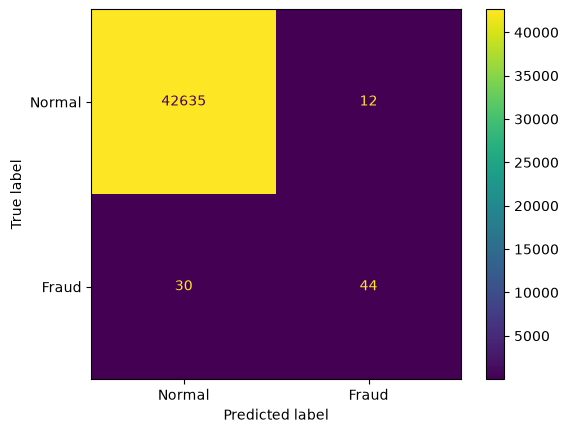

In [18]:
ConfusionMatrixDisplay(
    cm_baseline,
    display_labels=["Normal", "Fraud"]
).plot()

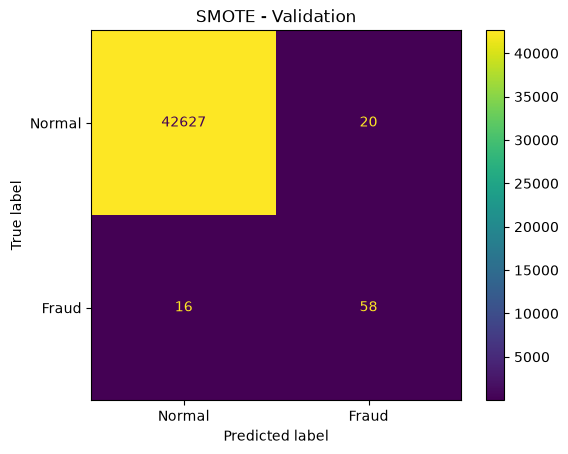

In [19]:
ConfusionMatrixDisplay(
    cm_smote,
    display_labels=["Normal", "Fraud"]
).plot()

plt.title("SMOTE - Validation")
plt.show()

In [20]:
print("Baseline")
print("False Positives:", cm_baseline[0,1])
print("False Negatives:", cm_baseline[1,0])

print("\nSMOTE")
print("False Positives:", cm_smote[0,1])
print("False Negatives:", cm_smote[1,0])

Baseline
False Positives: 12
False Negatives: 30

SMOTE
False Positives: 20
False Negatives: 16


Med SMOTE accepterar vi 8 fler false positive för att få **14 fler upptäckta** frauds och **14 färre missade frauds** på validation.

In [21]:
y_test_pred_baseline = baseline_model.predict(X_test_scaled)
y_test_prob_baseline = baseline_model.predict_proba(X_test_scaled)[:, 1]

y_test_pred_smote = smote_model.predict(X_test_scaled)
y_test_prob_smote = smote_model.predict_proba(X_test_scaled)[:, 1]

In [22]:
precision_test_baseline = precision_score(y_test, y_test_pred_baseline)
recall_test_baseline = recall_score(y_test, y_test_pred_baseline)
f1_test_baseline = f1_score(y_test, y_test_pred_baseline)
pr_auc_test_baseline = average_precision_score(
    y_test,
    y_test_prob_baseline
)

precision_test_smote = precision_score(y_test, y_test_pred_smote)
recall_test_smote = recall_score(y_test, y_test_pred_smote)
f1_test_smote = f1_score(y_test, y_test_pred_smote)
pr_auc_test_smote = average_precision_score(
    y_test,
    y_test_prob_smote
)

print("BASELINE – TEST")
print("Precision:", precision_test_baseline)
print("Recall:", recall_test_baseline)
print("F1-score:", f1_test_baseline)
print("PR-AUC:", pr_auc_test_baseline)

print("\nSMOTE – TEST")
print("Precision:", precision_test_smote)
print("Recall:", recall_test_smote)
print("F1-score:", f1_test_smote)
print("PR-AUC:", pr_auc_test_smote)

BASELINE – TEST
Precision: 0.9215686274509803
Recall: 0.6351351351351351
F1-score: 0.752
PR-AUC: 0.7498570639564623

SMOTE – TEST
Precision: 0.8
Recall: 0.7567567567567568
F1-score: 0.7777777777777778
PR-AUC: 0.7699537411600975


In [23]:
cm_test_baseline = confusion_matrix(
    y_test,
    y_test_pred_baseline
)

cm_test_smote = confusion_matrix(
    y_test,
    y_test_pred_smote
)

print("Baseline – Test")
print(cm_test_baseline)

print("\nSMOTE – Test")
print(cm_test_smote)

Baseline – Test
[[42644     4]
 [   27    47]]

SMOTE – Test
[[42634    14]
 [   18    56]]


På testdata ser vi samma mönster. SMOTE modellen hittar **9 fler frauds** och **missar 9 färre**, men kostar 10 extra false positives.

Test med RandomForest och olika SMOTE konfigurationer

In [24]:
from sklearn.ensemble import RandomForestClassifier

X_train_smote, y_train_smote = apply_smote(
    X_train,
    y_train,
    sampling_strategy=1.0,
    k_neighbors=5
)

rf_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(X_train_smote, y_train_smote)

y_val_pred = rf_smote.predict(X_val)
y_val_prob = rf_smote.predict_proba(X_val)[:, 1]

print("Precision:", precision_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F1:", f1_score(y_val, y_val_pred))
print("PR-AUC:", average_precision_score(y_val, y_val_prob))

Before SMOTE: Counter({0: 199020, 1: 344})
After SMOTE: Counter({0: 199020, 1: 199020})
k_neighbors: 5
Precision: 0.835820895522388
Recall: 0.7567567567567568
F1: 0.7943262411347518
PR-AUC: 0.8225207906698251


Jämför Bästa modellen i **fleramodeller.ipynb** med bästa SMOTE inställningar från denna notebook

In [25]:
X_train_smote, y_train_smote = apply_smote(
    X_train,
    y_train,
    sampling_strategy=0.01,
    k_neighbors=1
)

rf_smote_001 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote_001.fit(X_train_smote, y_train_smote)

y_val_pred_001 = rf_smote_001.predict(X_val)
y_val_prob_001 = rf_smote_001.predict_proba(X_val)[:, 1]

print("Precision:", precision_score(y_val, y_val_pred_001))
print("Recall:", recall_score(y_val, y_val_pred_001))
print("F1:", f1_score(y_val, y_val_pred_001))
print("PR-AUC:", average_precision_score(y_val, y_val_prob_001))

Before SMOTE: Counter({0: 199020, 1: 344})
After SMOTE: Counter({0: 199020, 1: 1990})
k_neighbors: 1
Precision: 0.8923076923076924
Recall: 0.7837837837837838
F1: 0.8345323741007195
PR-AUC: 0.8204441559277696


Precision, Recall och F1 ökar medan PR-AUC sjunker marginellt (0.002)

In [26]:
import numpy as np

def thresh_at_fp(y_true, probas, max_fp=12):
    thresh_best, tp_best, fp_best = 0.5, 0, 0

    for t in np.linspace(0.01, 1.0, 100):
        preds = (probas >= t).astype(int)

        fp = np.sum((preds == 1) & (y_true == 0))
        tp = np.sum((preds == 1) & (y_true == 1))

        if fp <= max_fp and tp > tp_best:
            tp_best = tp
            fp_best = fp
            thresh_best = t

    recall = tp_best / np.sum(y_true == 1)

    return thresh_best, tp_best, fp_best, recall

In [27]:
result_standard = thresh_at_fp(
    y_val,
    y_val_prob,
    max_fp=12
)

print("RF + standard-SMOTE:", result_standard)

RF + standard-SMOTE: (np.float64(0.46), np.int64(59), np.int64(12), np.float64(0.7972972972972973))


In [28]:
result_001 = thresh_at_fp(
    y_val,
    y_val_prob_001,
    max_fp=12
)

print("RF + SMOTE 0.01/1:", result_001)

RF + SMOTE 0.01/1: (np.float64(0.41000000000000003), np.int64(60), np.int64(12), np.float64(0.8108108108108109))


Undersöker andra SMOTE inställningar specifikt för RandomForest

In [ ]:
X_train_smote_0005, y_train_smote_0005 = apply_smote(
    X_train,
    y_train,
    sampling_strategy=0.0005,
    k_neighbors=1
)

rf_smote_0005 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote_0005.fit(X_train_smote_0005, y_train_smote_0005)

y_val_prob_0005 = rf_smote_0005.predict_proba(X_val)[:, 1]
y_val_pred_0005 = rf_smote_0005.predict(X_val)

print("Precision:", precision_score(y_val, y_val_pred_0005))
print("Recall:", recall_score(y_val, y_val_pred_0005))
print("F1:", f1_score(y_val, y_val_pred_0005))
print("PR-AUC:", average_precision_score(y_val, y_val_prob_0005))

Before SMOTE: Counter({0: 199020, 1: 344})
After SMOTE: Counter({0: 199020, 1: 995})
k_neighbors: 1
Precision: 0.90625
Recall: 0.7837837837837838
F1: 0.8405797101449275
PR-AUC: 0.8157193466332907


In [ ]:
result_0005 = thresh_at_fp(
    y_val,
    y_val_prob_0005,
    max_fp=12
)

print("RF + SMOTE 0.005/1:", result_0005)

RF + SMOTE 0.005/1: (np.float64(0.39), np.int64(59), np.int64(12), np.float64(0.7972972972972973))


In [31]:
X_train_smote_002, y_train_smote_002 = apply_smote(
    X_train,
    y_train,
    sampling_strategy=0.02,
    k_neighbors=1
)

rf_smote_002 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote_002.fit(X_train_smote_002, y_train_smote_002)

y_val_prob_002 = rf_smote_002.predict_proba(X_val)[:, 1]
y_val_pred_002 = rf_smote_002.predict(X_val)

print("Precision:", precision_score(y_val, y_val_pred_002))
print("Recall:", recall_score(y_val, y_val_pred_002))
print("F1:", f1_score(y_val, y_val_pred_002))
print("PR-AUC:", average_precision_score(y_val, y_val_prob_002))

Before SMOTE: Counter({0: 199020, 1: 344})
After SMOTE: Counter({0: 199020, 1: 3980})
k_neighbors: 1
Precision: 0.8923076923076924
Recall: 0.7837837837837838
F1: 0.8345323741007195
PR-AUC: 0.8251916638092892


In [33]:
result_002 = thresh_at_fp(
    y_val,
    y_val_prob_002,
    max_fp=12
)

print("RF + SMOTE 0.02/1:", result_002)

RF + SMOTE 0.02/1: (np.float64(0.4), np.int64(60), np.int64(12), np.float64(0.8108108108108109))


In [34]:
X_train_smote_005, y_train_smote_005 = apply_smote(
    X_train,
    y_train,
    sampling_strategy=0.05,
    k_neighbors=1
)

rf_smote_005 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote_005.fit(X_train_smote_005, y_train_smote_005)

y_val_prob_005 = rf_smote_005.predict_proba(X_val)[:, 1]
y_val_pred_005 = rf_smote_005.predict(X_val)

print("Precision:", precision_score(y_val, y_val_pred_005))
print("Recall:", recall_score(y_val, y_val_pred_005))
print("F1:", f1_score(y_val, y_val_pred_005))
print("PR-AUC:", average_precision_score(y_val, y_val_prob_005))

Before SMOTE: Counter({0: 199020, 1: 344})
After SMOTE: Counter({0: 199020, 1: 9951})
k_neighbors: 1
Precision: 0.8507462686567164
Recall: 0.7702702702702703
F1: 0.8085106382978723
PR-AUC: 0.820900666740342


In [35]:
result_005 = thresh_at_fp(
    y_val,
    y_val_prob_005,
    max_fp=12
)

print("RF + SMOTE 0.05/1:", result_005)

RF + SMOTE 0.05/1: (np.float64(0.48000000000000004), np.int64(58), np.int64(12), np.float64(0.7837837837837838))


Vinnare: RF + SMOTE 0.02